In [1]:
import sys
sys.path.append("../../../")

import sys
print(sys.executable)

/Users/serenelobo/Library/Mobile Documents/com~apple~CloudDocs/Documents/University/comp9517-computer vision/cs9517/basilisk/.venv/bin/python


In [2]:
from src.utils.dataset import load_dataset
from src.methods.deep_learning.deep_learning import DeepLearningDetector
from src.experiments.experiment_runner import (
    CleanExperiment,
    RandomSeverityExperiment,
    SeveritySweepExperiment,
    RandomCompositeExperiment
)
from src.evaluation.visualization import display_results
from src.experiments.transforms.corruptions import (
    GaussianNoise,
    GaussianBlur,
    MotionBlur,
    Brightness,
    Contrast
)

SEED=42

In [3]:

val_dataset = load_dataset("val")

detector = DeepLearningDetector()

detectors = {
    "deep_learning": detector
}

print(f"Loaded {len(val_dataset)} validation images")

Loaded 291 validation images


In [4]:
clean_results = CleanExperiment().run(val_dataset, detectors)

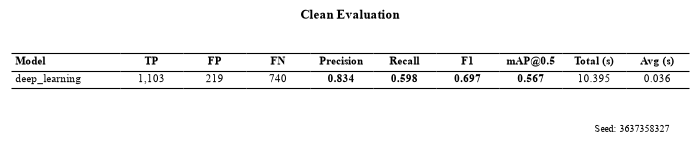

In [5]:
display_results(clean_results, seed=CleanExperiment().seed)

In [6]:
random_results = RandomSeverityExperiment(
    transform=GaussianBlur(),
    seed=SEED
).run(val_dataset, detectors)

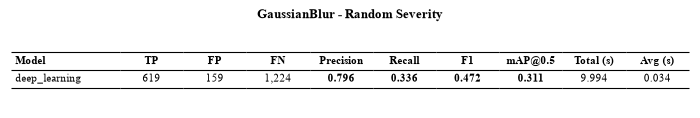

In [7]:
display_results(random_results)

In [8]:
severity_sweep = SeveritySweepExperiment(
    transform=GaussianBlur(),
    seed=SEED
).run(val_dataset, detectors)

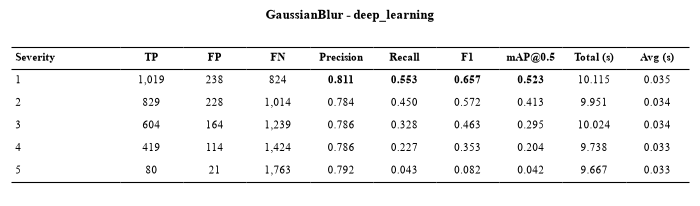

In [9]:
display_results(severity_sweep)

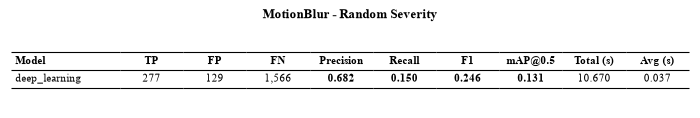

In [10]:
motion_random = RandomSeverityExperiment(
    transform=MotionBlur(),
    seed=SEED
).run(val_dataset, detectors)

display_results(motion_random)

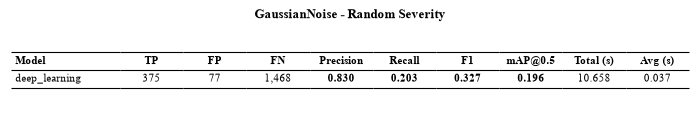

In [11]:
noise_random = RandomSeverityExperiment(
    transform=GaussianNoise(),
    seed=SEED
).run(val_dataset, detectors)

display_results(noise_random)

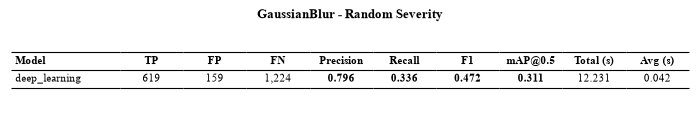

In [12]:
blur_random = RandomSeverityExperiment(
    transform=GaussianBlur(),
    seed=SEED
).run(val_dataset, detectors)

display_results(blur_random)

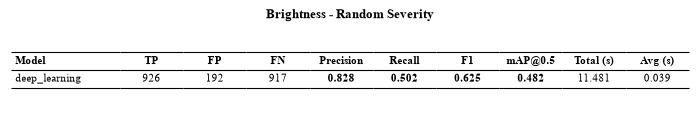

In [13]:
bright_random = RandomSeverityExperiment(
    transform=Brightness(),
    seed=SEED
).run(val_dataset, detectors)

display_results(bright_random)

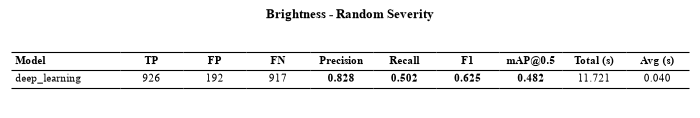

In [14]:
bright_random = RandomSeverityExperiment(
    transform=Brightness(),
    seed=SEED
).run(val_dataset, detectors)

display_results(bright_random)

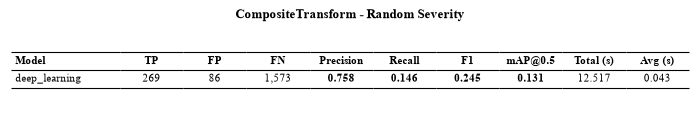

In [15]:
composite = RandomCompositeExperiment(
    seed=SEED
).run(val_dataset, detectors)

display_results(composite)